# Gaia DR4 acceleration-only fit: OHP simulated targets

This notebook fits Gaia epoch astrometry with an **acceleration (quadratic) model** of the star's sky motion: position + proper motion + acceleration + parallax. No Keplerian orbit is fit. This is the model behind a Gaia "acceleration solution", used when the orbital period is much longer than the ~5 yr DR4 baseline.

* `orbitize.gaia.DR4LogProb` reads the Gaia along-scan data and computes the likelihood. It is passed to `orbitize.system.System` through the `gaia` keyword.
* `System(acceleration_only=True)` replaces the Keplerian orbit parameters with the astrometric parameters from `Basis.set_gaia_dr4_priors` plus the accelerations from `Basis.set_acceleration_priors`. `set_acceleration_priors` raises an error if the DR4 parameters have not been set first.
* `orbitize.sampler.MCMC` samples the posterior, and `orbitize.results` holds it.
* `orbitize.plot.plot_dr4_acceleration` and `orbitize.plot.plot_dr4_orbit` plot the fit, and `orbitize.kepler.calc_orbit` computes the injected orbit used as a check.

**Data:** OHP 2025 Gaia splinter-session dataset (Delisle & Ségransan, [doi:10.82180/dace-gaia-ohp](https://doi.org/10.82180/dace-gaia-ohp)). These are simulated stars; `injected_solutions.csv` is the answer key. `target_7` is a 93-yr, 1100 $M_{\rm Jup}$ companion observed for 5 yr.

In [1]:
from pathlib import Path

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy import constants as consts

from orbitize import DATADIR, basis, gaia, kepler, plot, priors, sampler, system

c:\Users\tasni\orbitize\orbitize\hipparcos.py:232: SyntaxWarning: invalid escape sequence '\s'
  path_to_iad_file, skiprows=9, sep="\s+", nrows=1
c:\Users\tasni\orbitize\orbitize\hipparcos.py:246: SyntaxWarning: invalid escape sequence '\s'
  path_to_iad_file, skiprows=5, sep="\s+", nrows=1
c:\Users\tasni\orbitize\orbitize\hipparcos.py:528: SyntaxWarning: invalid escape sequence '\p'
  axes[0].set_xlabel("$\pi$ [mas]")
c:\Users\tasni\orbitize\orbitize\hipparcos.py:540: SyntaxWarning: invalid escape sequence '\m'
  axes[1].set_xlabel("$\mu_{{\\alpha_0^*}}$ [mas/yr]")
c:\Users\tasni\orbitize\orbitize\hipparcos.py:552: SyntaxWarning: invalid escape sequence '\m'
  axes[2].set_xlabel("$\mu_{{\\delta_0}}$ [mas/yr]")
c:\Users\tasni\orbitize\orbitize\hipparcos.py:568: SyntaxWarning: invalid escape sequence '\d'
  axes[4].set_xlabel("$\delta_0$ [mas]")


## Read in the OHP data

Each CSV row is one along-scan (AL) measurement: time `obs_time_tcb` (JD, TCB), position `centroid_pos_al` and error `centroid_pos_error_al` (mas), the AL parallax factor, and the scan position angle $\psi$ (rad). The OHP files (`target_*.csv` and `injected_solutions.csv`) ship with orbitize! in `orbitize/example_data/`, so they are read from `DATADIR`.

In [2]:
DATA_DIR = Path(DATADIR)

target_file = "target_7.csv"  # change this to fit another target

solutions = pd.read_csv(DATA_DIR / "injected_solutions.csv")
truth_row = solutions[solutions.filename == target_file].iloc[0]
target_name = f"{target_file.removesuffix('.csv')}: {truth_row.comment}"

## Likelihood object

`gaia.DR4LogProb` reads the CSV with `read_input.from_ohp_file` and models the AL position at epoch $t_i$ as

$$
w_i = \varpi\, f_{{\rm AL},i}
+ \left[\alpha^*_0 + \mu_{\alpha^*} \Delta t_i + g_{\alpha^*} \Delta t_i^2\right] \sin\psi_i
+ \left[\delta_0 + \mu_\delta \Delta t_i + g_\delta \Delta t_i^2\right] \cos\psi_i
$$

with $\Delta t_i = t_i - t_{\rm ref}$ in years and $t_{\rm ref}$ = J2017.5. Units are mas, mas/yr and mas/yr². $g$ is the $\Delta t^2$ coefficient, i.e. half the sky-plane acceleration (the same convention as orbitize's Keplerian + acceleration fit). The acceleration terms are included when `acc_ra`/`acc_dec` are fitted parameters. `compute_lnlike` is the Gaussian likelihood the sampler calls. The acceleration reaches it through `System.compute_all_orbits`, which returns the star's $g\,\Delta t^2$ offsets, and `plot._model_along_scan_dr4` returns $w_i$ for one parameter vector.

In [3]:
gaia_al = gaia.DR4LogProb(gaia_num=0, dr4_filepath=DATA_DIR / target_file)  # no real source ID

print(target_name)
print(f"{gaia_al.n_obs} AL measurements over {np.ptp(gaia_al.dt_yr):.2f} yr")
gaia_al.data_table[:5]

target_7: Long-period degenerate orbit (acceleration solution)
88 AL measurements over 5.03 yr


obs_time_tcb,centroid_pos_al,centroid_pos_error_al,parallax_factor_al,scan_pos_angle,field_of_view
d,mas,mas,,rad,
float64,float64,float64,float64,float64,int64
57021.09462034982,92.56961203970047,0.07026234,0.63927573,-1.74797762,1
57021.16865041014,92.19739090890761,0.06715982,0.6404742,-1.75107922,2
57061.57578303991,141.65890251858548,0.06449053,-0.4728041,-1.16061562,1
57061.64973958023,141.3789243036706,0.07790377,-0.47046134,-1.16536748,2
57084.33135046018,-69.91318982400082,0.07315645,0.45317352,-2.79776043,1


## Set up the System

There is no relative astrometry or RV, so `data_table=None` and `num_secondary_bodies=0`; all the data enter through `gaia=gaia_al`. With `acceleration_only=True` the fitted parameters are

* `plx` (uniform 0–1000 mas),
* `pm_ra`, `pm_dec`, `alpha0`, `delta0` from `Basis.set_gaia_dr4_priors`,
* `acc_ra`, `acc_dec` from `Basis.set_acceleration_priors`,

all with broad uniform priors. No mass parameter is added. `compute_all_orbits` computes no Keplerian orbit; it returns only the star's acceleration offsets $g\,\Delta t^2$, which `DR4LogProb` adds to its linear model. `stellar_or_system_mass=1.0` and `plx=10.0` are placeholders that are not used.

Here `alpha0`/`delta0` are the fitted position offsets [mas]. The `System` keywords of the same name (reference RA/Dec in degrees) are only needed when the star's absolute RA/Dec is in the data table, so they are not set.

In [4]:
acc_sys = system.System(
    num_secondary_bodies=0,
    data_table=None,
    stellar_or_system_mass=1.0,
    plx=10.0,
    gaia=gaia_al,
    acceleration_only=True,
)
labels = list(acc_sys.labels)

for label, prior in zip(labels, acc_sys.sys_priors):
    print(f"{label:8s} {prior}")

plx      Uniform
pm_ra    Uniform
pm_dec   Uniform
alpha0   Uniform
delta0   Uniform
acc_ra   Uniform
acc_dec  Uniform


## Starting point

The model is linear in its parameters, so `plot._model_along_scan_dr4` evaluated at each unit vector gives the design-matrix column for that parameter. A weighted least-squares fit then gives a starting point and covariance for the walkers, and a $\chi^2$ check of the quoted errors.

In [5]:
def model_al(theta):
    return plot._model_along_scan_dr4(theta, acc_sys, gaia_al)


A = np.column_stack([model_al(e) for e in np.eye(len(labels))])
w, err = gaia_al.centroid_pos_al, gaia_al.centroid_pos_error_al
wt = 1.0 / err**2
ls_cov = np.linalg.inv(A.T @ (A * wt[:, None]))
ls_best = ls_cov @ (A.T @ (wt * w))

resid = w - model_al(ls_best)
chi2 = np.sum((resid / err) ** 2)
dof = len(w) - len(labels)
print(f"chi2 = {chi2:.1f} for {dof} dof (reduced chi2 = {chi2 / dof:.2f})")

chi2 = 120.5 for 81 dof (reduced chi2 = 1.49)


## Sample the posterior

`orbitize.sampler.MCMC` runs `ptemcee`; with `num_temps=1` there is no parallel tempering. Walkers start in a Gaussian ball drawn from the least-squares covariance. `MCMC.curr_pos` has shape `(num_temps, num_walkers, num_params)`.

In [6]:
n_walkers = 50
burn_steps = 1000
num_steps = 5000

acc_sampler = sampler.MCMC(acc_sys, num_temps=1, num_walkers=n_walkers, num_threads=1)
acc_sampler.curr_pos = np.random.default_rng(0).multivariate_normal(
    ls_best, ls_cov, size=(acc_sampler.num_temps, n_walkers)
)
acc_sampler.run_sampler(n_walkers * num_steps, burn_steps=burn_steps, thin=1)

results = acc_sampler.results
post = pd.DataFrame(results.post, columns=list(results.labels))
post["|acc|"] = np.hypot(post.acc_ra, post.acc_dec)

Starting Burn in
1000/1000 steps of burn-in complete
Burn in complete. Sampling posterior now.
5000/5000 steps completed
Run complete


## Check convergence

Walker traces after burn-in, from `MCMC.examine_chains`. They should look stationary.

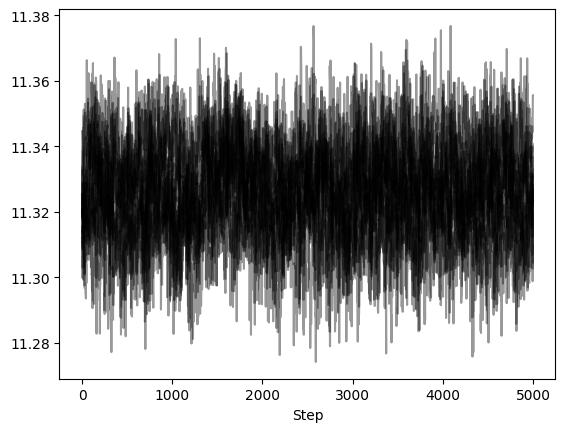

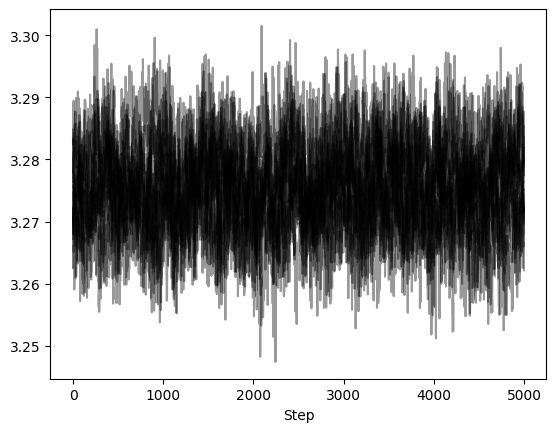

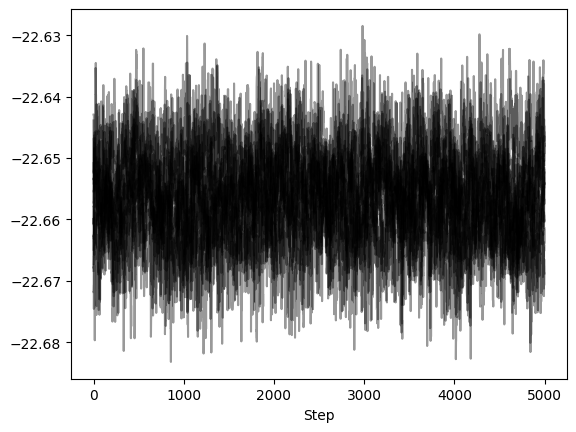

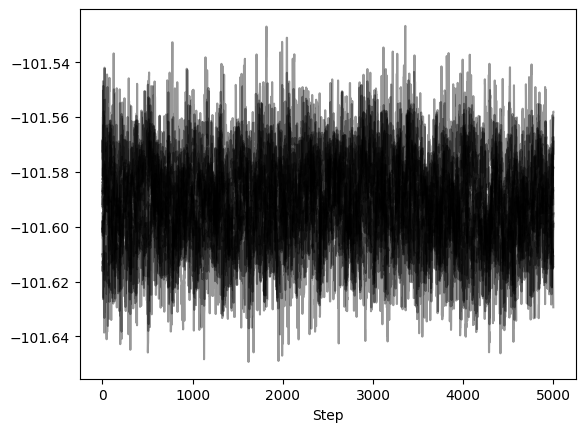

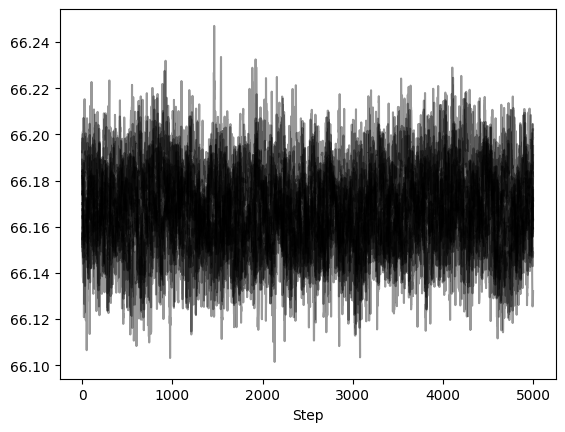

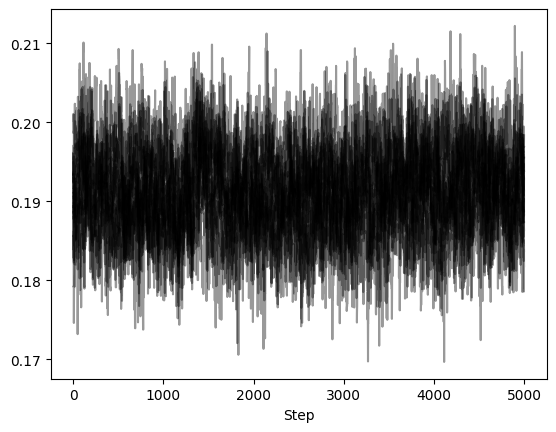

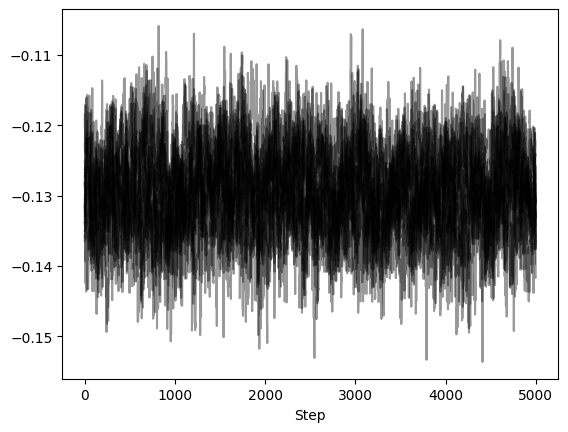

In [7]:
figs = acc_sampler.examine_chains(param_list=labels, n_walkers=16, transparency=0.4)

## Results

`Results.print_results` has no units for `acc_ra`/`acc_dec`, so the summary is printed here.

In [8]:
UNITS = {
    "plx": "mas",
    "alpha0": "mas",
    "delta0": "mas",
    "pm_ra": "mas/yr",
    "pm_dec": "mas/yr",
    "acc_ra": "mas/yr^2",
    "acc_dec": "mas/yr^2",
    "|acc|": "mas/yr^2",
}

for name in labels + ["|acc|"]:
    p16, med, p84 = np.percentile(post[name], [16, 50, 84])
    print(f"{name:8s} {med:10.4f}  (+{p84 - med:.4f} / -{med - p16:.4f})  {UNITS[name]}")

plx         11.3261  (+0.0126 / -0.0130)  mas
pm_ra        3.2753  (+0.0066 / -0.0066)  mas/yr
pm_dec     -22.6563  (+0.0071 / -0.0071)  mas/yr
alpha0    -101.5918  (+0.0159 / -0.0158)  mas
delta0      66.1671  (+0.0167 / -0.0164)  mas
acc_ra       0.1914  (+0.0052 / -0.0053)  mas/yr^2
acc_dec     -0.1294  (+0.0057 / -0.0056)  mas/yr^2
|acc|        0.2310  (+0.0059 / -0.0058)  mas/yr^2


## Compare to the injected acceleration

Since the data are simulated, we can compute the injected orbit's sky-plane acceleration at J2017.5 and compare it with the fit. `kepler.calc_orbit` gives the photocentre position at three epochs around J2017.5, and the $\Delta t^2$ coefficient is half the second derivative (finite differences).

The injected orbit is given as a photocentre semi-major axis $a_0$ [mas], period $P$, and mean anomaly $M_0$ at J2017.5. To pass it to `calc_orbit`:

* `sma` $= a_0$ and `plx` $= 1$, so the offsets come out in mas,
* `mtot` from Kepler's third law, so that orbitize's period equals $P$,
* `tau` from $M_0$ with `basis.tp_to_tau`.

In [9]:
def injected_acceleration(row, ref_epoch_mjd, h=0.01):
    """dt^2 coefficient (RA*, Dec) of the injected photocentre orbit at
    ref_epoch_mjd [mas/yr^2], i.e. the quantity fitted as acc_ra/acc_dec."""
    period_yr = row.P_d / 365.25
    # M0 is the mean anomaly at J2017.5 (= ref_epoch_mjd)
    tp = ref_epoch_mjd - np.radians(row.M0_deg) / (2 * np.pi) * row.P_d
    mtot = 4 * np.pi**2 * (row.a0_mas * u.au) ** 3 / (consts.G * (row.P_d * u.day) ** 2)

    epochs = ref_epoch_mjd + np.array([-h, 0.0, h]) * 365.25
    ra, dec, _, _ = kepler.calc_orbit(
        epochs,
        sma=row.a0_mas,
        ecc=row.e,
        inc=np.radians(row.i_deg),
        aop=np.radians(row.omega_deg),
        pan=np.radians(row.big_omega_deg),
        tau=basis.tp_to_tau(tp, ref_epoch_mjd, period_yr),
        plx=1.0,
        mtot=mtot.to_value(u.Msun),
        tau_ref_epoch=ref_epoch_mjd,
    )
    pos = np.array([ra, dec])  # (RA*, Dec) at -h, 0, +h
    return (pos[:, 2] - 2 * pos[:, 1] + pos[:, 0]) / (2 * h**2)


if np.isfinite(truth_row.P_d):
    true_acc_ra, true_acc_dec = injected_acceleration(truth_row, gaia_al.ref_epoch_mjd)
else:  # single star: no acceleration injected
    true_acc_ra, true_acc_dec = 0.0, 0.0
truth = {
    "plx": truth_row.parallax_mas,
    "acc_ra": true_acc_ra,
    "acc_dec": true_acc_dec,
    "|acc|": np.hypot(true_acc_ra, true_acc_dec),
}

for name, true in truth.items():
    p16, med, p84 = np.percentile(post[name], [16, 50, 84])
    sigma = (p84 - p16) / 2
    print(
        f"{name:8s} fit {med:9.4f} +/- {sigma:.4f}   true {true:9.4f}   "
        f"offset {(med - true) / sigma:+.1f} sigma"
    )

plx      fit   11.3261 +/- 0.0128   true   11.3253   offset +0.1 sigma
acc_ra   fit    0.1914 +/- 0.0052   true    0.1914   offset +0.0 sigma
acc_dec  fit   -0.1294 +/- 0.0057   true   -0.1246   offset -0.8 sigma
|acc|    fit    0.2310 +/- 0.0059   true    0.2284   offset +0.5 sigma


## Corner plot

`Results.plot_corner` (a wrapper around `corner.corner`). orbitize has no default axis labels for `acc_ra`/`acc_dec`, so the labels are passed in. Injected values in orange.

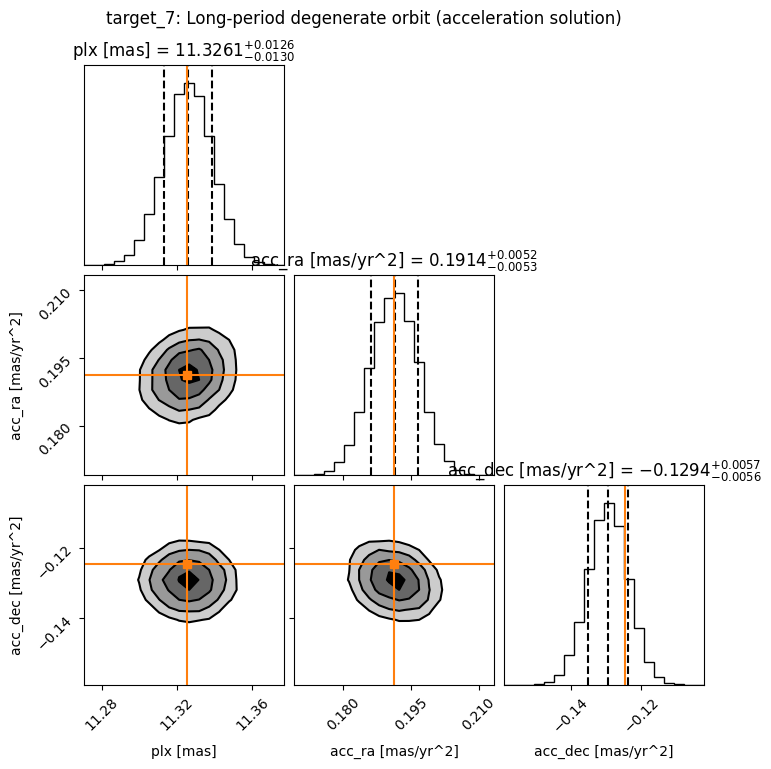

In [10]:
plot_names = ["plx", "acc_ra", "acc_dec"]
fig = results.plot_corner(
    param_list=plot_names,
    labels=[f"{n} [{UNITS[n]}]" for n in plot_names],
    truths=[truth[n] for n in plot_names],
    truth_color="tab:orange",
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_fmt=".4f",
    plot_datapoints=False,
    fill_contours=True,
    max_n_ticks=3,
)
fig.suptitle(target_name, y=1.02)
plt.show()

## Along-scan data and residuals

Top: the acceleration signal, i.e. data minus the fitted parallax, position and proper motion, with the fitted acceleration term overplotted. Bottom: residuals of the full fit. Both use the least-squares best fit and `plot._model_along_scan_dr4`.

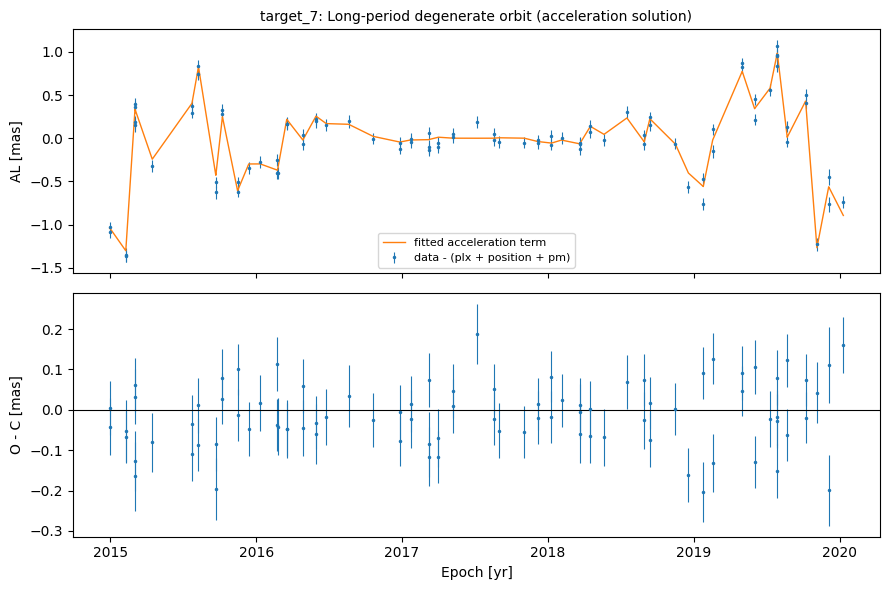

In [11]:
no_acc = ls_best.copy()
no_acc[[acc_sys.param_idx["acc_ra"], acc_sys.param_idx["acc_dec"]]] = 0.0
signal = w - model_al(no_acc)
acc_model = model_al(ls_best) - model_al(no_acc)

t_yr = gaia_al.gaia_epoch  # decimal year (TCB)
order = np.argsort(t_yr)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax1.errorbar(t_yr, signal, err, fmt=".", ms=3, lw=0.8, label="data - (plx + position + pm)")
ax1.plot(t_yr[order], acc_model[order], "tab:orange", lw=1, label="fitted acceleration term")
ax1.set_ylabel("AL [mas]")
ax1.legend(fontsize=8)
ax1.set_title(target_name, fontsize=10)

ax2.errorbar(t_yr, resid, err, fmt=".", ms=3, lw=0.8)
ax2.axhline(0, color="k", lw=0.8)
ax2.set_ylabel("O - C [mas]")
ax2.set_xlabel("Epoch [yr]")
fig.tight_layout()
plt.show()

## Keplerian + acceleration fit

Everything above fits an acceleration only. Here the same `target_7` data are fitted with a full Keplerian orbit **plus** a constant acceleration, `System(acceleration_and_keplerian_fit=True)`. This model is meant for a star with a companion whose orbit fits inside the DR4 baseline, plus a distant companion that only shows up as a trend. This section repeats the steps above for it.

**What to expect.** `target_7` has one companion, on a 93-yr orbit, and no outer trend, so in this model the injected values are that orbit with zero acceleration. But over 5 yr the orbit is just a curve, and the acceleration term can fit the same curve. The data cannot fully tell the two apart, so expect wide posteriors and strong correlations between the acceleration and the orbit parameters. That degeneracy is why Gaia gives an acceleration solution, not an orbit, for stars like this.

The variables here start with `kep_`, so the acceleration-only results above (`results`, `post`, `acc_sys`, ...) are left alone for the plots further down.

In [12]:
kep_file = target_file  # the same target as above

kep_row = solutions[solutions.filename == kep_file].iloc[0]
kep_name = f"{kep_file.removesuffix('.csv')}: Keplerian + acceleration fit"

## Keplerian + acceleration: likelihood object

The same `gaia.DR4LogProb`, now with the star's Keplerian reflex motion $(\Delta\alpha^*_{\rm orb}, \Delta\delta_{\rm orb})$ added to the model:

$$
w_i = \varpi\, f_{{\rm AL},i}
+ \left[\alpha^*_0 + \mu_{\alpha^*} \Delta t_i + g_{\alpha^*} \Delta t_i^2 + \Delta\alpha^*_{{\rm orb},i}\right] \sin\psi_i
+ \left[\delta_0 + \mu_\delta \Delta t_i + g_\delta \Delta t_i^2 + \Delta\delta_{{\rm orb},i}\right] \cos\psi_i .
$$

A new `DR4LogProb` is made for this `System`, from the same file.

In [13]:
kep_gaia = gaia.DR4LogProb(gaia_num=0, dr4_filepath=DATA_DIR / kep_file)  # no real source ID

print(kep_name)
print(f"{kep_gaia.n_obs} AL measurements over {np.ptp(kep_gaia.dt_yr):.2f} yr")
print(f"median AL error {np.median(kep_gaia.centroid_pos_error_al):.3f} mas")

target_7: Keplerian + acceleration fit
88 AL measurements over 5.03 yr
median AL error 0.067 mas


## Keplerian + acceleration: set up the System

One companion with its mass fitted (`fit_secondary_mass=True`) and `acceleration_and_keplerian_fit=True`. The fitted parameters are

* the orbit: `sma1`, `ecc1`, `inc1`, `aop1`, `pan1`, `tau1`,
* `plx` (Gaussian prior around the catalogue value, ±0.5 mas),
* `pm_ra`, `pm_dec`, `alpha0`, `delta0` from `Basis.set_gaia_dr4_priors`,
* `acc_ra`, `acc_dec` from `Basis.set_acceleration_priors`,
* the masses `m1` and `m0` (Gaussian prior on `m0`, $1.0 \pm 0.1\,M_\odot$).

`compute_all_orbits` returns the star's Keplerian reflex motion with $g\,\Delta t^2$ added on top. The priors on `sma1` and `ecc1` follow the `Gaia_DR4_OHP` tutorial. The `m1` prior goes up to $2\,M_\odot$, because the companion here is about $1.07\,M_\odot$ (1118 $M_{
m Jup}$).

In [14]:
kep_sys = system.System(
    num_secondary_bodies=1,
    data_table=None,
    stellar_or_system_mass=1.0,
    mass_err=0.1,
    plx=kep_row.parallax_mas,
    plx_err=0.5,
    fit_secondary_mass=True,
    gaia=kep_gaia,
    acceleration_and_keplerian_fit=True,
)
kep_idx = kep_sys.param_idx
kep_sys.sys_priors[kep_idx["sma1"]] = priors.LogUniformPrior(0.05, 100.0)
kep_sys.sys_priors[kep_idx["ecc1"]] = priors.UniformPrior(0.0, 0.99)
kep_sys.sys_priors[kep_idx["m1"]] = priors.LogUniformPrior(1e-4, 2.0)
kep_labels = list(kep_sys.labels)

for label, prior in zip(kep_labels, kep_sys.sys_priors):
    print(f"{label:8s} {prior}")

sma1     Log Uniform
ecc1     Uniform
inc1     Sine
aop1     Uniform
pan1     Uniform
tau1     Uniform
plx      Gaussian
pm_ra    Uniform
pm_dec   Uniform
alpha0   Uniform
delta0   Uniform
acc_ra   Uniform
acc_dec  Uniform
m1       Log Uniform
m0       Gaussian


## Keplerian + acceleration: starting point

The model is no longer linear, so the starting point takes two steps.

1. **The injected values in orbitize's parameters**, following the `Gaia_DR4_OHP` tutorial: `sma1` from Kepler's third law with $m_0 = 1\,M_\odot$, `aop1` and `pan1` shifted by 180° (the CSV gives the star's orbit, orbitize the companion's), and `tau1` from $M_0$ at the DR4 reference epoch, and zero acceleration. As a check, $\chi^2$ there should be close to the number of points, and much worse with the orbit switched off.
2. **Least squares for the rest.** With the orbit and parallax held at those values, the model is linear in position, proper motion and acceleration, so a weighted least-squares fit (as above) gives their starting point and covariance. This is also the **fixed-orbit check**: with the true orbit held fixed, the acceleration should come out consistent with zero.

A blind search over all periods would need parallel tempering and many more steps (see the `Gaia_DR4_OHP` tutorial). Here the orbit starts at the injected values, and the sampler then explores how far the orbit and the acceleration can trade off.

In [15]:
P_yr = kep_row.P_d / 365.25
m_b = kep_row.m_b / 1047.57  # Msun
kep_truth = {
    "sma1": (P_yr**2 * (1.0 + m_b)) ** (1 / 3),
    "ecc1": kep_row.e,
    "inc1": np.radians(kep_row.i_deg),
    "aop1": np.radians((kep_row.omega_deg + 180) % 360),
    "pan1": np.radians((kep_row.big_omega_deg + 180) % 360),
    "tau1": (-kep_row.M0_deg / 360 + (kep_gaia.ref_epoch_mjd - kep_sys.tau_ref_epoch) / kep_row.P_d) % 1,
    "plx": kep_row.parallax_mas,
    "pm_ra": kep_row.mu_alpha_mas_yr,
    "pm_dec": kep_row.mu_delta_mas_yr,
    "alpha0": kep_row.alpha_mas,
    "delta0": kep_row.delta_mas,
    "acc_ra": 0.0,
    "acc_dec": 0.0,
    "m1": m_b,
    "m0": 1.0,
}
kep_p0 = np.array([kep_truth[label] for label in kep_labels])


def kep_model_al(theta):
    return plot._model_along_scan_dr4(theta, kep_sys, kep_gaia)


kep_w, kep_err = kep_gaia.centroid_pos_al, kep_gaia.centroid_pos_error_al


def kep_chi2(theta):
    return np.sum(((kep_w - kep_model_al(theta)) / kep_err) ** 2)


# 1. checks at the injected values
no_orbit = kep_p0.copy()
no_orbit[kep_idx["m1"]] = 1e-8
print(f"chi2 at injected values: {kep_chi2(kep_p0):9.1f}  ({kep_gaia.n_obs} points)")
print(f"chi2 without orbit:      {kep_chi2(no_orbit):9.1f}")
print(f"acceleration-only fit:   {chi2:9.1f}  (least squares, above)")

# 2. least squares for the linear parameters, orbit and plx held fixed
kep_lin = ["pm_ra", "pm_dec", "alpha0", "delta0", "acc_ra", "acc_dec"]
lin_idx = [kep_idx[label] for label in kep_lin]
base = kep_p0.copy()
base[lin_idx] = 0.0
A_kep = np.column_stack(
    [kep_model_al(base + np.eye(len(kep_labels))[i]) - kep_model_al(base) for i in lin_idx]
)
kep_wt = 1.0 / kep_err**2
kep_ls_cov = np.linalg.inv(A_kep.T @ (A_kep * kep_wt[:, None]))
kep_ls_best = kep_ls_cov @ (A_kep.T @ (kep_wt * (kep_w - kep_model_al(base))))

kep_start = base.copy()
kep_start[lin_idx] = kep_ls_best
kep_dof = kep_gaia.n_obs - len(kep_labels)
print(f"\nchi2 at starting point: {kep_chi2(kep_start):.1f} for {kep_dof} dof "
      f"(reduced chi2 = {kep_chi2(kep_start) / kep_dof:.2f})")
for label, value, sigma in zip(kep_lin, kep_ls_best, np.sqrt(np.diag(kep_ls_cov))):
    print(f"  {label:8s} {value:10.4f} +/- {sigma:.4f}   (injected {kep_truth[label]:.4f})")

chi2 at injected values:     117.7  (88 points)
chi2 without orbit:      126865972.7
acceleration-only fit:       120.5  (least squares, above)

chi2 at starting point: 116.9 for 73 dof (reduced chi2 = 1.60)
  pm_ra        3.6541 +/- 0.0066   (injected 3.6544)
  pm_dec     -23.2511 +/- 0.0071   (injected -23.2515)
  alpha0       0.0101 +/- 0.0158   (injected 0.0024)
  delta0       0.0041 +/- 0.0166   (injected -0.0028)
  acc_ra      -0.0030 +/- 0.0052   (injected 0.0000)
  acc_dec     -0.0033 +/- 0.0056   (injected 0.0000)


## Keplerian + acceleration: sample the posterior

The same sampler setup as above. The position, proper motion and acceleration start in a Gaussian ball drawn from the least-squares covariance; the orbit parameters, parallax and masses start in a small ball around the injected values. This takes several minutes: the Keplerian model is about ten times slower than the acceleration-only one. **This run is not converged.** Because of the degeneracy, the walkers are still spreading out from their starting ball at the end, and getting a converged posterior would need parallel tempering and hours of sampling. The results below therefore show where the walkers have got to, not the real posterior: the real one is much wider.

In [16]:
kep_walkers = 100
kep_burn = 5000
kep_steps = 20000


ball = {"sma1": 1e-3, "tau1": 5e-3, "m1": 1e-4}  # spread 0.01 for the rest
spread = np.array([ball.get(label, 0.01) for label in kep_labels])

kep_sampler = sampler.MCMC(kep_sys, num_temps=1, num_walkers=kep_walkers, num_threads=1)
rng = np.random.default_rng(1)
pos0 = kep_start + spread * rng.normal(size=(kep_sampler.num_temps, kep_walkers, len(kep_labels)))
pos0[..., lin_idx] = rng.multivariate_normal(
    kep_ls_best, kep_ls_cov, size=(kep_sampler.num_temps, kep_walkers)
)
kep_sampler.curr_pos = pos0
kep_sampler.run_sampler(kep_walkers * kep_steps, burn_steps=kep_burn, thin=1)

kep_results = kep_sampler.results
kep_post = pd.DataFrame(kep_results.post, columns=list(kep_results.labels))
kep_post["|acc|"] = np.hypot(kep_post.acc_ra, kep_post.acc_dec)

Starting Burn in
5000/5000 steps of burn-in complete
Burn in complete. Sampling posterior now.
20000/20000 steps completed
Run complete


## Keplerian + acceleration: check convergence

Walker traces after burn-in. They should look stationary.

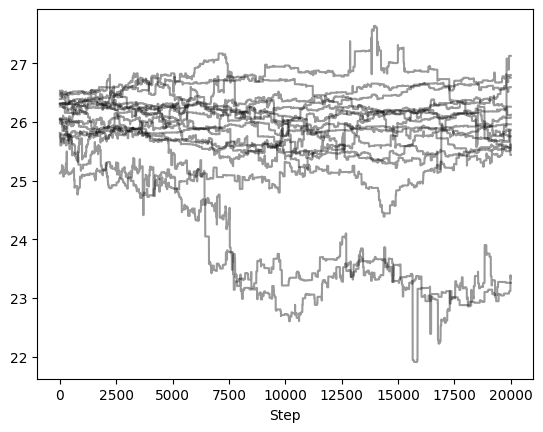

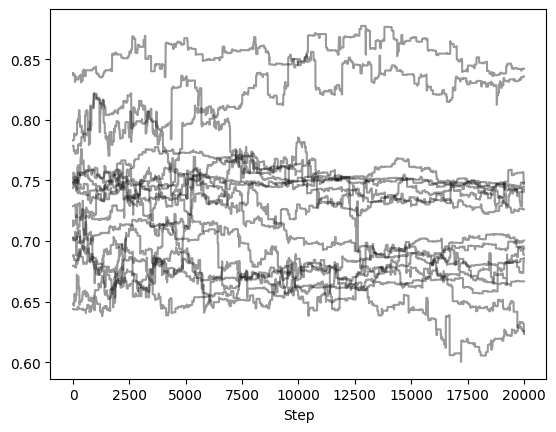

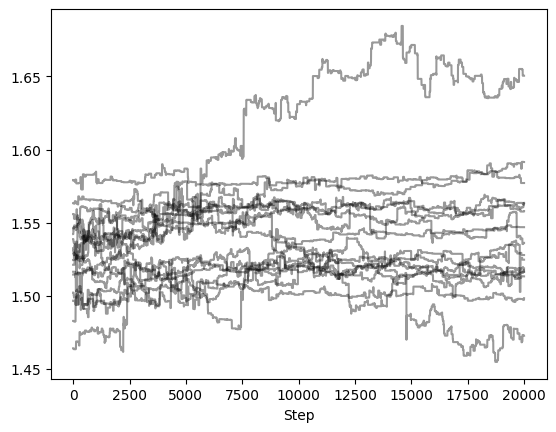

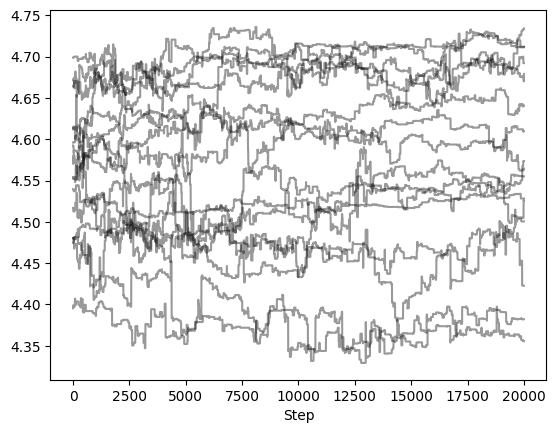

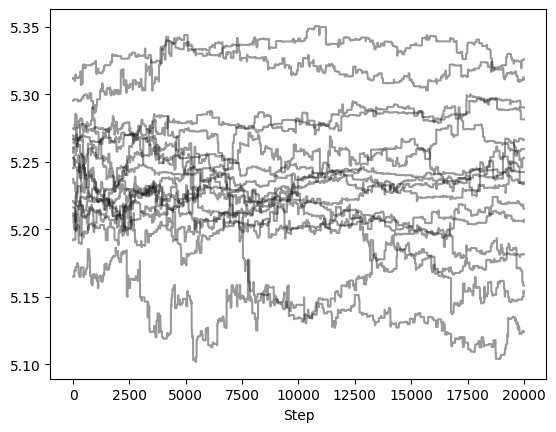

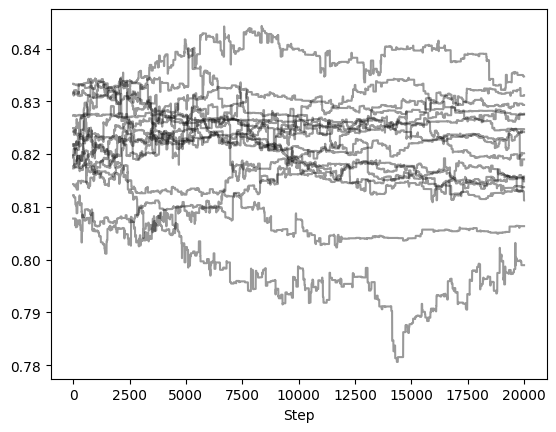

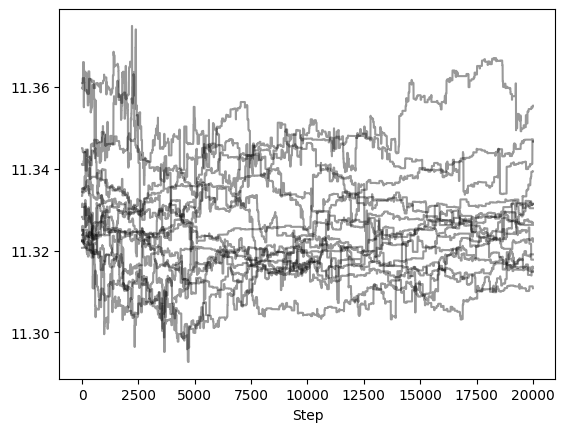

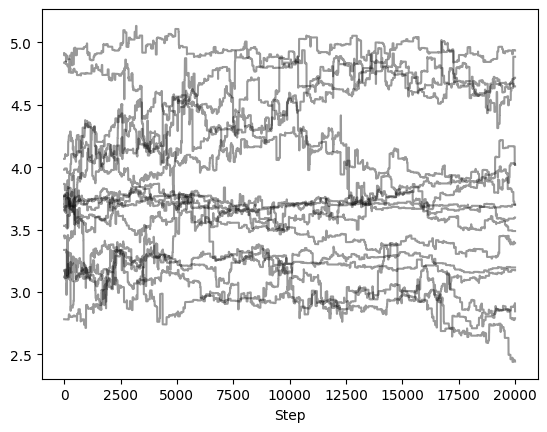

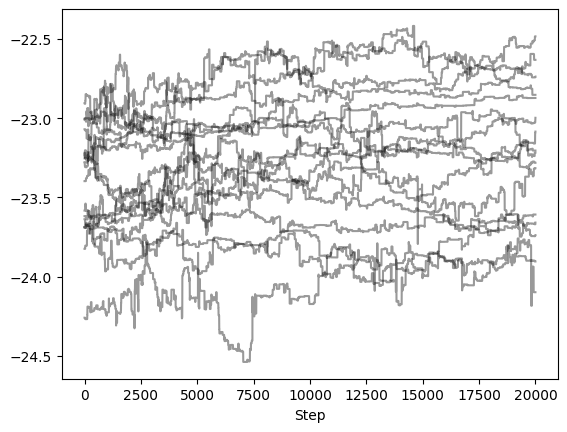

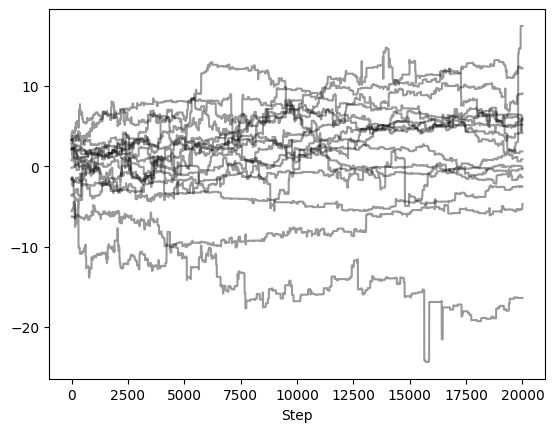

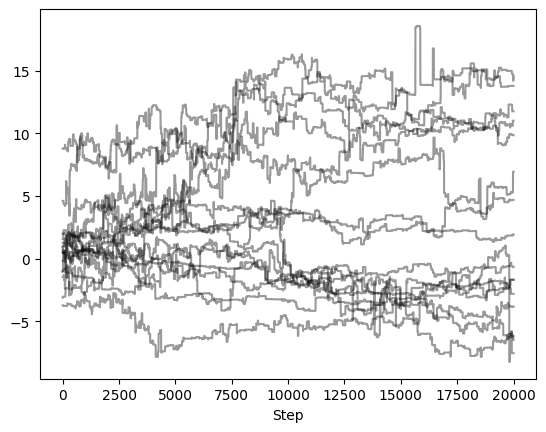

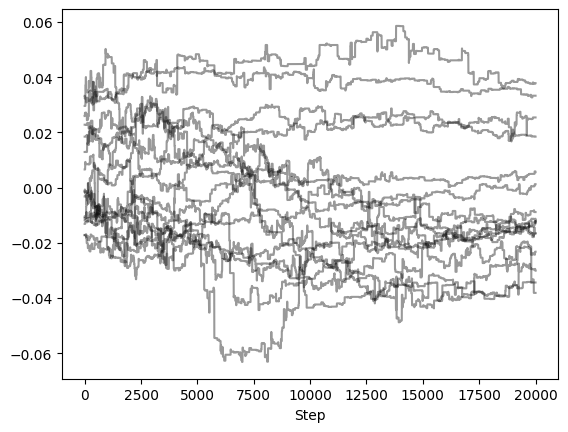

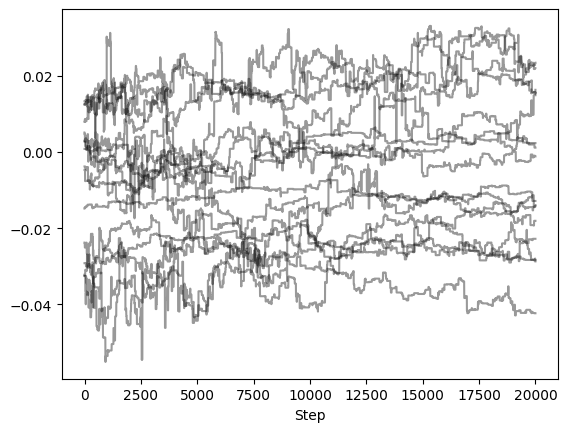

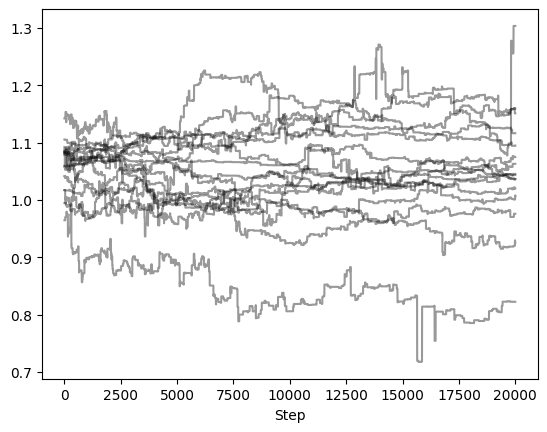

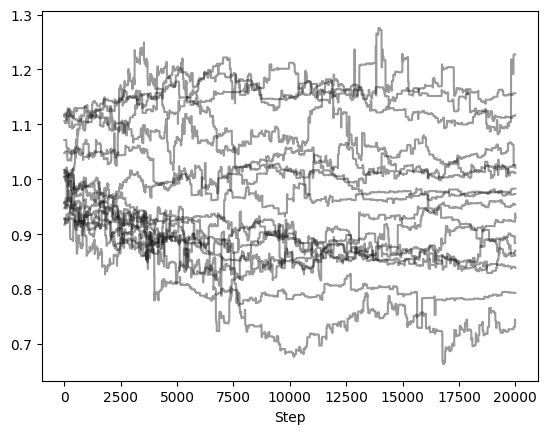

In [17]:
figs = kep_sampler.examine_chains(param_list=kep_labels, n_walkers=16, transparency=0.4)

## Keplerian + acceleration: results

Angles are converted to degrees and `m1` to $M_{\rm Jup}$. Because the run is not converged, these error bars mostly reflect the small starting ball, not the data.

In [18]:
KEP_UNITS = {
    "sma1": ("au", 1.0),
    "ecc1": ("", 1.0),
    "inc1": ("deg", np.degrees(1.0)),
    "aop1": ("deg", np.degrees(1.0)),
    "pan1": ("deg", np.degrees(1.0)),
    "tau1": ("", 1.0),
    "plx": ("mas", 1.0),
    "pm_ra": ("mas/yr", 1.0),
    "pm_dec": ("mas/yr", 1.0),
    "alpha0": ("mas", 1.0),
    "delta0": ("mas", 1.0),
    "acc_ra": ("mas/yr^2", 1.0),
    "acc_dec": ("mas/yr^2", 1.0),
    "|acc|": ("mas/yr^2", 1.0),
    "m1": ("M_Jup", 1047.57),
    "m0": ("M_sun", 1.0),
}

for name, (unit, k) in KEP_UNITS.items():
    p16, med, p84 = np.percentile(kep_post[name] * k, [16, 50, 84])
    print(f"{name:8s} {med:10.4f}  (+{p84 - med:.4f} / -{med - p16:.4f})  {unit}")

sma1        26.1180  (+0.4891 / -0.6840)  au
ecc1         0.7183  (+0.0667 / -0.0690)  
inc1        88.3814  (+2.0236 / -2.3684)  deg
aop1       261.5024  (+6.9769 / -6.1514)  deg
pan1       301.0472  (+2.2306 / -2.6187)  deg
tau1         0.8204  (+0.0091 / -0.0140)  
plx         11.3238  (+0.0175 / -0.0169)  mas
pm_ra        3.7224  (+0.7226 / -0.7400)  mas/yr
pm_dec     -23.2532  (+0.4300 / -0.4620)  mas/yr
alpha0       0.1868  (+5.1051 / -5.3304)  mas
delta0       1.2452  (+6.5253 / -4.5737)  mas
acc_ra       0.0006  (+0.0273 / -0.0301)  mas/yr^2
acc_dec     -0.0094  (+0.0228 / -0.0187)  mas/yr^2
|acc|        0.0288  (+0.0195 / -0.0160)  mas/yr^2
m1        1108.8594  (+56.0898 / -70.8499)  M_Jup
m0           1.0198  (+0.1179 / -0.1192)  M_sun


## Keplerian + acceleration: compare to the injected values

The offset is (median − injected) / σ, with σ half the 16–84% range. The injected acceleration is zero. Offsets near zero here are **not** a sign of success: the walkers started at the injected values and have not moved far from them. `aop1` and `pan1` are left out: from astrometry alone they are only defined up to a shared 180° flip.

In [19]:
kep_truth["|acc|"] = np.hypot(kep_truth["acc_ra"], kep_truth["acc_dec"])

for name in ["sma1", "ecc1", "inc1", "m1", "plx", "acc_ra", "acc_dec", "|acc|"]:
    unit, k = KEP_UNITS[name]
    p16, med, p84 = np.percentile(kep_post[name] * k, [16, 50, 84])
    sigma = (p84 - p16) / 2
    true = kep_truth[name] * k
    print(
        f"{name:8s} fit {med:9.4f} +/- {sigma:.4f}   true {true:9.4f}   "
        f"offset {(med - true) / sigma:+.1f} sigma  {unit}"
    )

sma1     fit   26.1180 +/- 0.5866   true   26.1673   offset -0.1 sigma  au
ecc1     fit    0.7183 +/- 0.0678   true    0.7150   offset +0.0 sigma  
inc1     fit   88.3814 +/- 2.1960   true   88.1547   offset +0.1 sigma  deg
m1       fit 1108.8594 +/- 63.4698   true 1118.4494   offset -0.2 sigma  M_Jup
plx      fit   11.3238 +/- 0.0172   true   11.3253   offset -0.1 sigma  mas
acc_ra   fit    0.0006 +/- 0.0287   true    0.0000   offset +0.0 sigma  mas/yr^2
acc_dec  fit   -0.0094 +/- 0.0208   true    0.0000   offset -0.5 sigma  mas/yr^2
|acc|    fit    0.0288 +/- 0.0177   true    0.0000   offset +1.6 sigma  mas/yr^2


## Keplerian + acceleration: corner plot

`Results.plot_corner` converts `inc1` to degrees and `m1` to $M_{\rm Jup}$, so the injected values are converted the same way. Injected values in orange.

The patchy, lumpy contours are what an unconverged run looks like: a converged posterior would be smooth. The correlations are already visible, though. Over 5 yr the 93-yr orbit and the acceleration produce nearly the same curve, so a change in the orbit (`sma1`, `ecc1`, `m1`) can be made up for by a change in the acceleration (see the `acc_ra` and `acc_dec` rows).

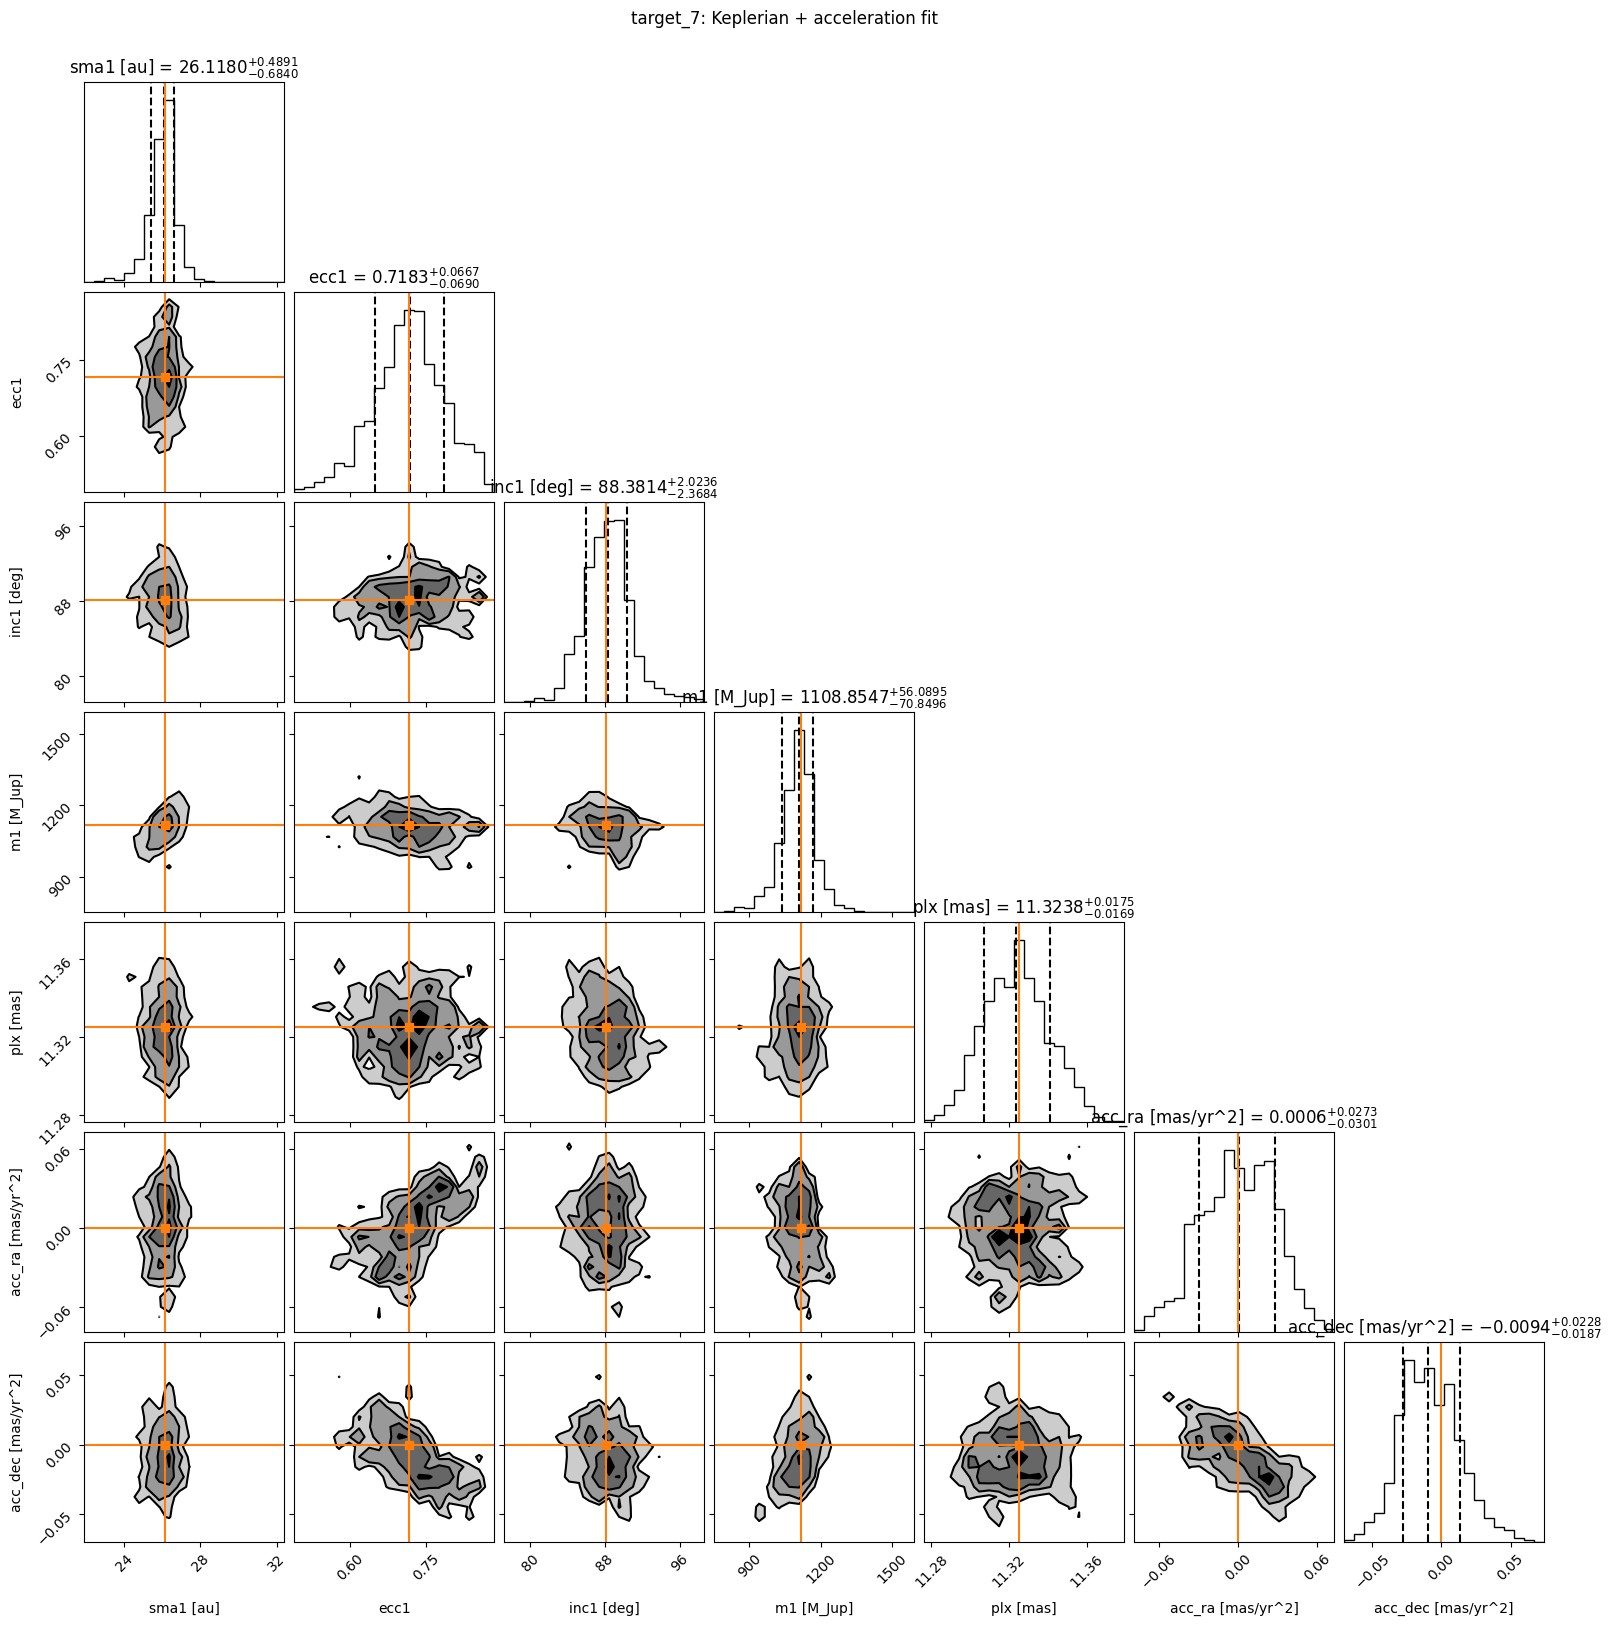

In [20]:
kep_names = ["sma1", "ecc1", "inc1", "m1", "plx", "acc_ra", "acc_dec"]
kep_corner_labels = [
    "sma1 [au]", "ecc1", "inc1 [deg]", "m1 [M_Jup]", "plx [mas]",
    "acc_ra [mas/yr^2]", "acc_dec [mas/yr^2]",
]
fig = kep_results.plot_corner(
    param_list=kep_names,
    labels=kep_corner_labels,
    truths=[kep_truth[n] * KEP_UNITS[n][1] for n in kep_names],
    truth_color="tab:orange",
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,
    title_fmt=".4f",
    plot_datapoints=False,
    fill_contours=True,
    max_n_ticks=3,
)
fig.suptitle(kep_name, y=1.02)
plt.show()

## Keplerian + acceleration: along-scan data and residuals

The same as the acceleration-only version above, with the orbit split out. All three panels use the maximum-likelihood sample.

* Top: data minus the fitted parallax, position and proper motion, with the fitted acceleration + orbit.
* Middle: data minus parallax, position, proper motion and acceleration, with the fitted orbit alone.
* Bottom: residuals of the full fit.

The AL model only exists at the observed scan angles, so the models are drawn as points at the data epochs.

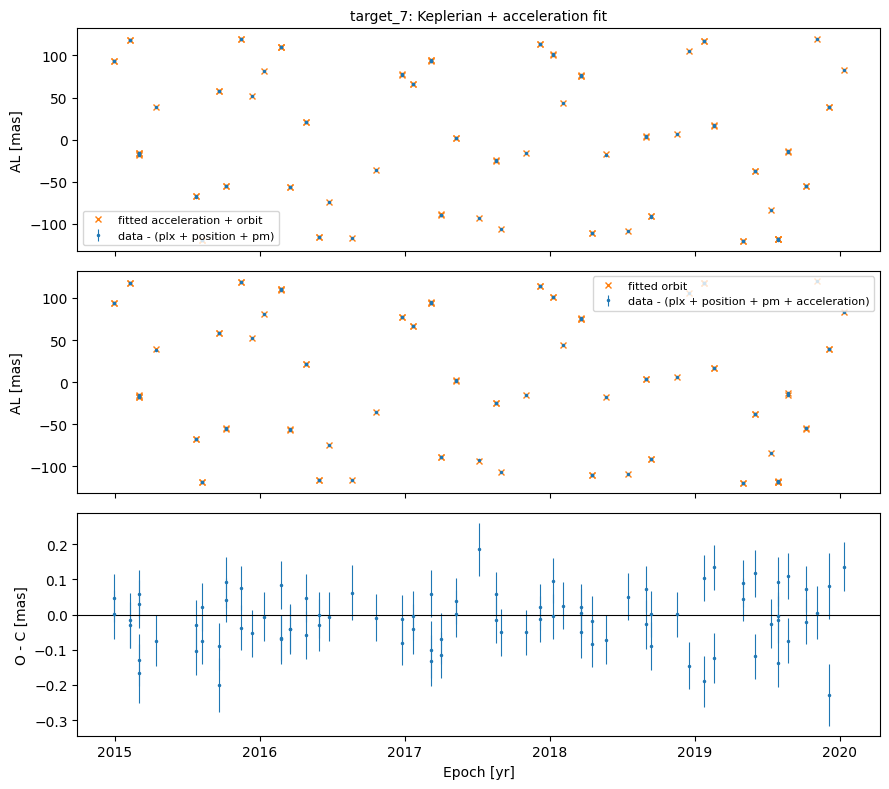

In [21]:
kep_best = kep_results.post[np.nanargmax(kep_results.lnlike)]
kep_acc_idx = [kep_idx["acc_ra"], kep_idx["acc_dec"]]

linear_only = kep_best.copy()  # parallax + position + proper motion
linear_only[kep_acc_idx] = 0.0
linear_only[kep_idx["m1"]] = 0.0
acc_only = linear_only.copy()
acc_only[kep_acc_idx] = kep_best[kep_acc_idx]

kep_linear = kep_model_al(linear_only)
kep_acc_part = kep_model_al(acc_only) - kep_linear
kep_orbit_part = kep_model_al(kep_best) - kep_model_al(acc_only)
kep_resid = kep_w - kep_model_al(kep_best)

t_kep = kep_gaia.gaia_epoch  # decimal year (TCB)
fig, axes = plt.subplots(3, 1, figsize=(9, 8), sharex=True)
panels = [
    (kep_w - kep_linear, kep_acc_part + kep_orbit_part, "data - (plx + position + pm)", "fitted acceleration + orbit"),
    (kep_w - kep_linear - kep_acc_part, kep_orbit_part, "data - (plx + position + pm + acceleration)", "fitted orbit"),
]
for ax, (data, model, data_label, model_label) in zip(axes, panels):
    ax.errorbar(t_kep, data, kep_err, fmt=".", ms=3, lw=0.8, label=data_label)
    ax.plot(t_kep, model, "x", color="tab:orange", ms=5, label=model_label)
    ax.set_ylabel("AL [mas]")
    ax.legend(fontsize=8)
axes[0].set_title(kep_name, fontsize=10)

axes[2].errorbar(t_kep, kep_resid, kep_err, fmt=".", ms=3, lw=0.8)
axes[2].axhline(0, color="k", lw=0.8)
axes[2].set_ylabel("O - C [mas]")
axes[2].set_xlabel("Epoch [yr]")
fig.tight_layout()
plt.show()

## Sky motion vs time

`plot.plot_dr4_acceleration` splits the model into its parts and draws them on the sky against time. Each row removes one more part of the fitted model from the data:

| Row | Lines (50 posterior draws) | Data with these parts removed |
|---|---|---|
| top | position + proper motion + acceleration + orbit | nothing |
| middle | acceleration + orbit, colored by `acc_ra` | position + proper motion |
| bottom | orbit only | position + proper motion + acceleration |

Here there is no orbit, so the orbit term is zero: the middle row is the acceleration alone, $g\,\Delta t^2$, and the bottom row's lines sit at zero, with the residuals of the full fit as its points. The left column is $\Delta\alpha^*$ and the right column is $\Delta\delta$, both in mas. The middle row is the acceleration signal itself: a straight-line motion would leave flat points around zero there. In a Keplerian + acceleration fit the bottom row shows the orbit, and that row is colored instead.

**Parallax is not shown.** The OHP files only give the along-scan parallax factor $f_{\rm AL}$, not separate RA and Dec factors, so $\varpi f_{\rm AL}$ is subtracted from the data before plotting.

**From 1D measurements to sky points.** Gaia measures only the position along the scan, in the direction $(\sin\psi, \cos\psi)$ in $(\alpha^*, \delta)$. For each posterior draw, a measurement is placed on the sky by moving that draw's model position along the scan direction by the along-scan residual:

$$
(\alpha^*, \delta)_i = (\alpha^*, \delta)_{{\rm model},i} + \left(w_i - w_{{\rm model},i}\right)(\sin\psi_i, \cos\psi_i).
$$

The position across the scan is not measured, so it comes from the model. This is the Gaia version of the Hipparcos IAD tangent points.

**Error bars.**
* Thick: the scatter of these points over the posterior draws, i.e. the uncertainty from subtracting the model.
* Thin: the along-scan uncertainty projected onto each axis, $\sigma_{\rm AL}/\lvert\sin\psi\rvert$ for $\alpha^*$ and $\sigma_{\rm AL}/\lvert\cos\psi\rvert$ for $\delta$. Scans nearly perpendicular to an axis (projection below 0.3, `min_projection`) are not drawn, because their error along that axis blows up.

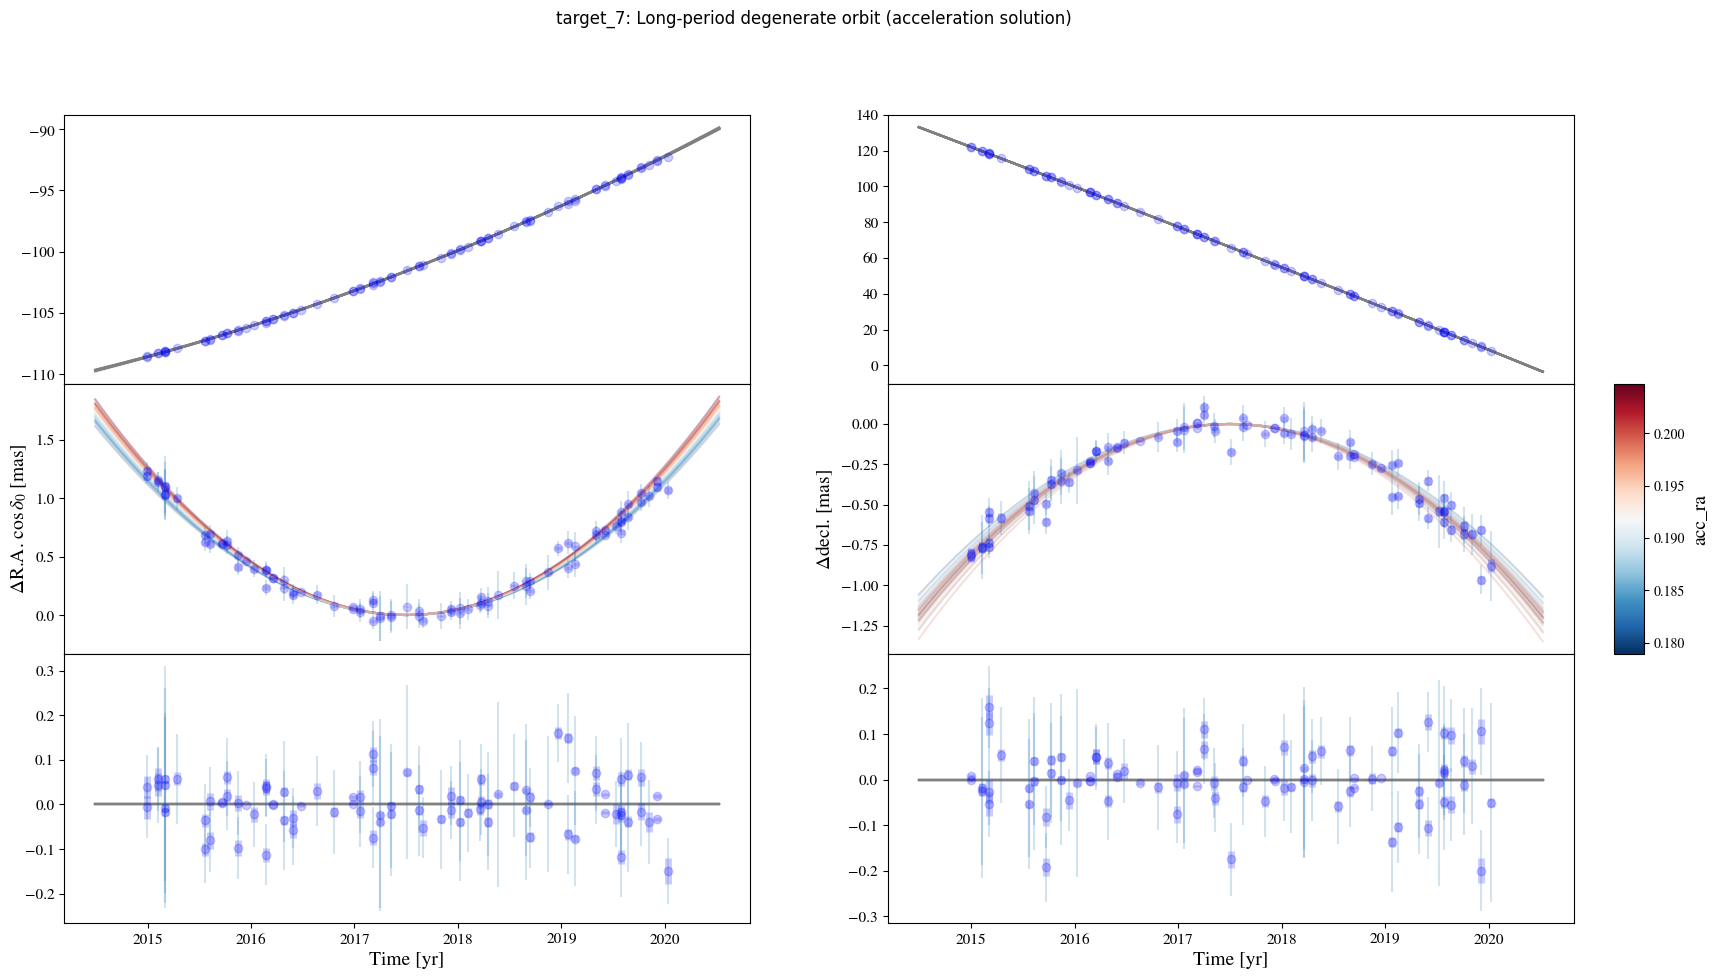

In [22]:
fig = plot.plot_dr4_acceleration(results, acc_sys, num_orbits_to_plot=50, cbar_param="acc_ra")
fig.suptitle(target_name)
plt.show()

## The whole orbit

The fit only sees 5 yr of a 93-yr orbit. To put that in context, these plots draw the **injected** orbit (from `injected_solutions.csv`, computed with `kepler.calc_orbit` as in `injected_acceleration`) over one full period, from periastron to periastron. An acceleration-only fit has no period of its own, so the period and phase come from the injected orbit.

* **Grey:** the injected photocentre orbit, $\Delta\alpha^*$ (left) and $\Delta\delta$ (right).
* **Orange:** the fitted acceleration, $g\,\Delta t^2$, for 50 posterior draws, drawn over the Gaia window ± 3 yr. The fit cannot tell a constant offset or a straight-line motion apart from position and proper motion, so the parabola is anchored to the orbit's position and velocity at J2017.5.
* **Blue:** the Gaia points, i.e. the least-squares fitted acceleration plus each AL residual moved along its scan direction, on the same anchor.
* **Shaded band:** the Gaia DR4 window. The insets zoom in on it.

The first figure uses time on the x-axis; the second uses orbital phase, $\phi = \left[(t - t_p)/P\right] \bmod 1$, with $t_p$ the periastron time and $P$ the injected period. Over the Gaia window the parabola follows the orbit closely, and it drifts away from it within a few years on either side: the acceleration is only a local approximation of the orbit.

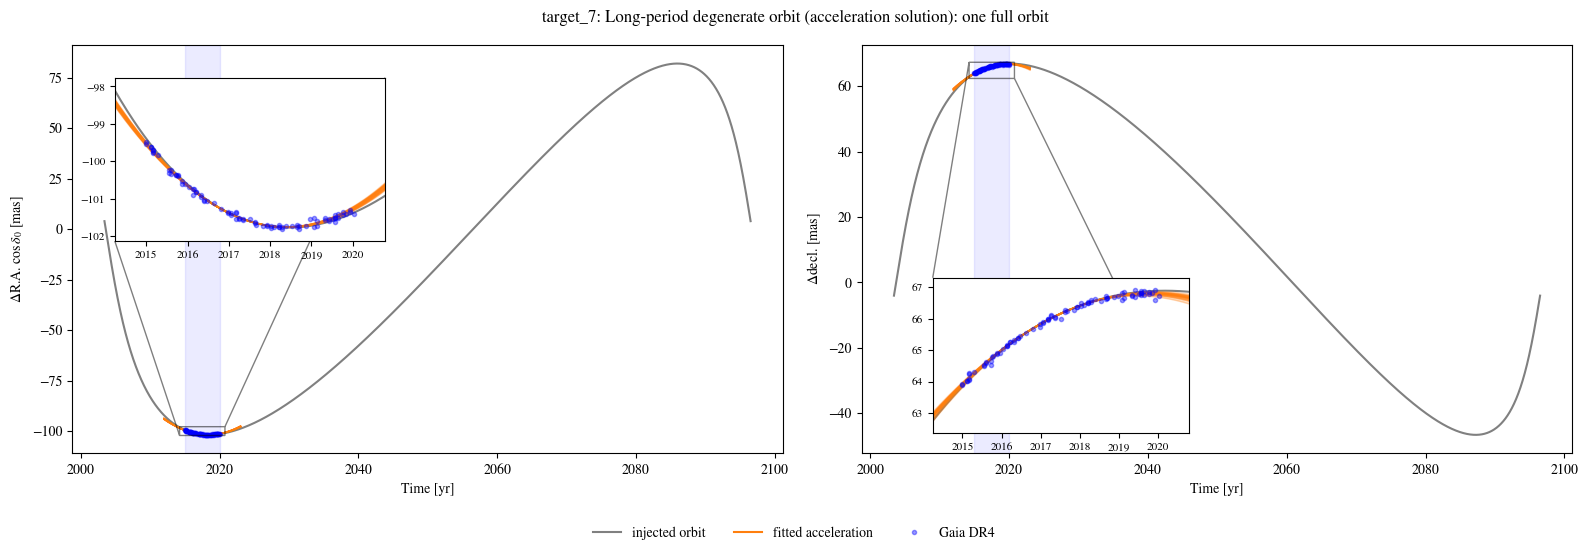

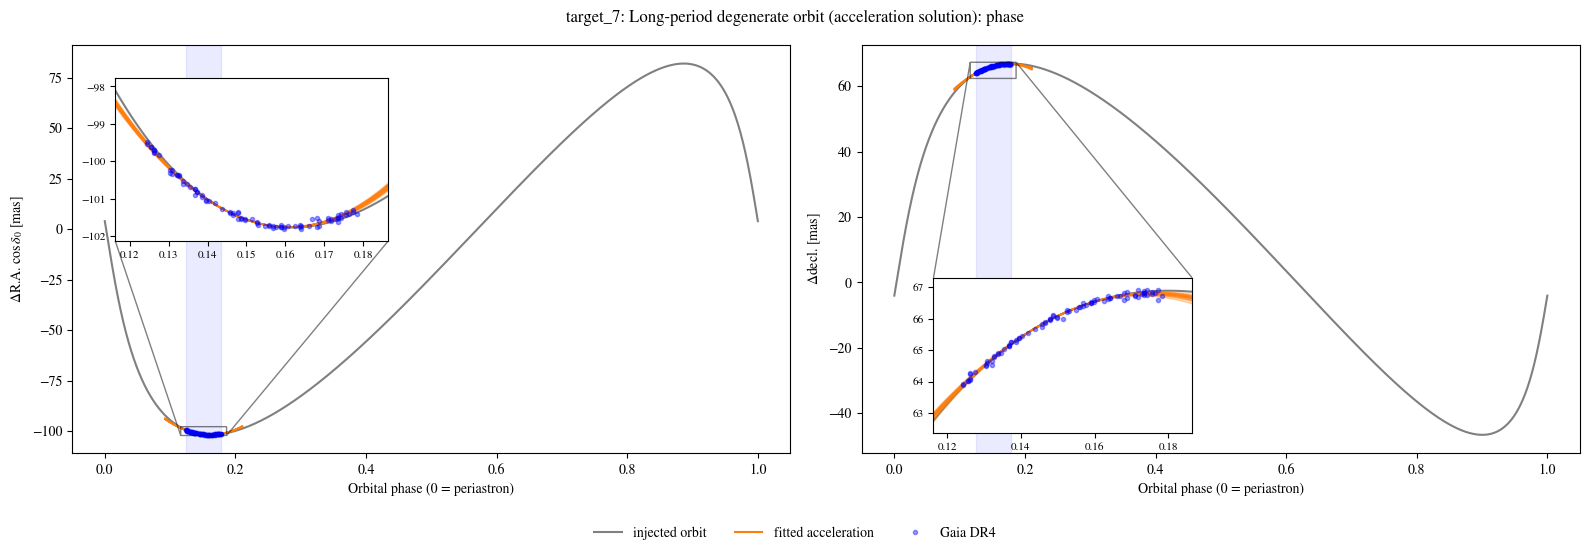

In [23]:
def injected_orbit(row, epochs_mjd, ref_epoch_mjd):
    """Injected photocentre orbit (RA*, Dec) [mas] at epochs_mjd, with the
    same conversions as injected_acceleration."""
    period_yr = row.P_d / 365.25
    tp = ref_epoch_mjd - np.radians(row.M0_deg) / (2 * np.pi) * row.P_d
    mtot = 4 * np.pi**2 * (row.a0_mas * u.au) ** 3 / (consts.G * (row.P_d * u.day) ** 2)
    ra, dec, _, _ = kepler.calc_orbit(
        epochs_mjd,
        sma=row.a0_mas,
        ecc=row.e,
        inc=np.radians(row.i_deg),
        aop=np.radians(row.omega_deg),
        pan=np.radians(row.big_omega_deg),
        tau=basis.tp_to_tau(tp, ref_epoch_mjd, period_yr),
        plx=1.0,
        mtot=mtot.to_value(u.Msun),
        tau_ref_epoch=ref_epoch_mjd,
    )
    return np.array([ra, dec])


ref = gaia_al.ref_epoch_mjd
P_d = truth_row.P_d
tp = ref - np.radians(truth_row.M0_deg) / (2 * np.pi) * P_d  # periastron before J2017.5

# one full orbit, periastron to periastron
t_orbit = tp + np.linspace(0, 1, 3000) * P_d
orbit = injected_orbit(truth_row, t_orbit, ref)

# the fit only sees the orbit up to a straight line: anchor the fitted
# acceleration to the orbit's position and velocity at J2017.5
h = 0.01  # yr
pos_m, pos_0, pos_p = injected_orbit(truth_row, ref + np.array([-h, 0, h]) * 365.25, ref).T
vel = (pos_p - pos_m) / (2 * h)
acc_idx = [acc_sys.param_idx["acc_ra"], acc_sys.param_idx["acc_dec"]]
scan = np.array([gaia_al.sin_scan, gaia_al.cos_scan])

# Gaia points: fitted acceleration + AL residual along the scan, on the anchor
dt = gaia_al.dt_yr
points = (
    pos_0[:, None] + vel[:, None] * dt
    + ls_best[acc_idx][:, None] * dt**2
    + resid * scan
)

# fitted acceleration for posterior draws, over the Gaia window +/- 3 yr
dt_win = np.linspace(dt.min() - 3, dt.max() + 3, 200)
draws = post[["acc_ra", "acc_dec"]].sample(50, random_state=0).to_numpy()
parabolas = (
    pos_0[None, :, None] + vel[None, :, None] * dt_win
    + draws[:, :, None] * dt_win**2
)


# inset positions (axes fraction) chosen to sit clear of target_7's orbit
inset_pos = [[0.06, 0.52, 0.38, 0.4], [0.1, 0.05, 0.36, 0.38]]


def plot_full_orbit(x_of_mjd, xlabel, title):
    """Injected orbit over one period, the Gaia points and the fitted
    acceleration, against x_of_mjd(epochs_mjd). Insets zoom on the Gaia window."""
    x_orbit = x_of_mjd(t_orbit)
    x_data = x_of_mjd(gaia_al.epochs_mjd)
    x_win = x_of_mjd(ref + dt_win * 365.25)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
    for c, (ax, ylabel) in enumerate(
        zip(axes, [r"$\Delta$R.A. $\cos{\delta_0}$ [mas]", r"$\Delta$decl. [mas]"])
    ):
        inset = ax.inset_axes(inset_pos[c])
        for a in (ax, inset):
            a.plot(x_orbit, orbit[c], color="grey", lw=1.5, label="injected orbit")
            for p in parabolas:
                a.plot(x_win, p[c], color="tab:orange", alpha=0.2, lw=1)
            a.errorbar(
                x_data, points[c], ls="", marker="o", ms=3, color="blue", alpha=0.4,
                label="Gaia DR4",
            )
        ax.axvspan(x_data.min(), x_data.max(), color="blue", alpha=0.08)
        ax.plot([], [], color="tab:orange", label="fitted acceleration")

        # zoom on the Gaia window
        pad = 0.15 * np.ptp(x_data)
        inset.set_xlim(x_data.min() - pad, x_data.max() + pad)
        in_win = (x_orbit > x_data.min() - pad) & (x_orbit < x_data.max() + pad)
        lo, hi = orbit[c][in_win].min(), orbit[c][in_win].max()
        inset.set_ylim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))
        inset.tick_params(labelsize=8)
        ax.indicate_inset_zoom(inset, edgecolor="k")

        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
    handles, leg_labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, leg_labels, loc="lower center", ncol=3, frameon=False)
    fig.suptitle(title)
    fig.tight_layout(rect=[0, 0.07, 1, 1])
    return fig


if np.isfinite(P_d):
    with plt.style.context(
        ["default", {"font.family": "stixgeneral", "mathtext.fontset": "stix"}]
    ):
        to_year = lambda mjd: 2000.0 + (mjd - 51544.5) / 365.25  # Julian years
        plot_full_orbit(to_year, "Time [yr]", f"{target_name}: one full orbit")
        plt.show()

        to_phase = lambda mjd: ((mjd - tp) / P_d) % 1
        plot_full_orbit(to_phase, "Orbital phase (0 = periastron)", f"{target_name}: phase")
        plt.show()
else:
    print("No injected orbit for this target (single star).")

## Acceleration on the sky

`plot.plot_dr4_orbit` draws the star's track on the sky (colored by epoch) and the Gaia AL measurements placed along their scan directions, as in the plot above. In an acceleration-only fit there is no Keplerian orbit, so `System.compute_all_orbits` returns only the star's $g\,\Delta t^2$ offsets. The pink track **is** the acceleration, with position, proper motion and parallax removed. Because $g\,\Delta t^2$ always points along $g$, it is a straight line from the origin rather than a curve: the star moves in to the origin at J2017.5 and back out along the same line. The $\Delta t^2$ curvature shows up against time, in the plot above.

`show_acceleration=True` overplots the acceleration part of each track as a dashed grey line, from `plot._split_star_offsets_dr4`. Here it lies on top of the pink track. In an `acceleration_and_keplerian_fit` the two differ, and the dashed line separates the acceleration from the orbit. There is no companion panel (`include_planet`) because `num_secondary_bodies=0`.

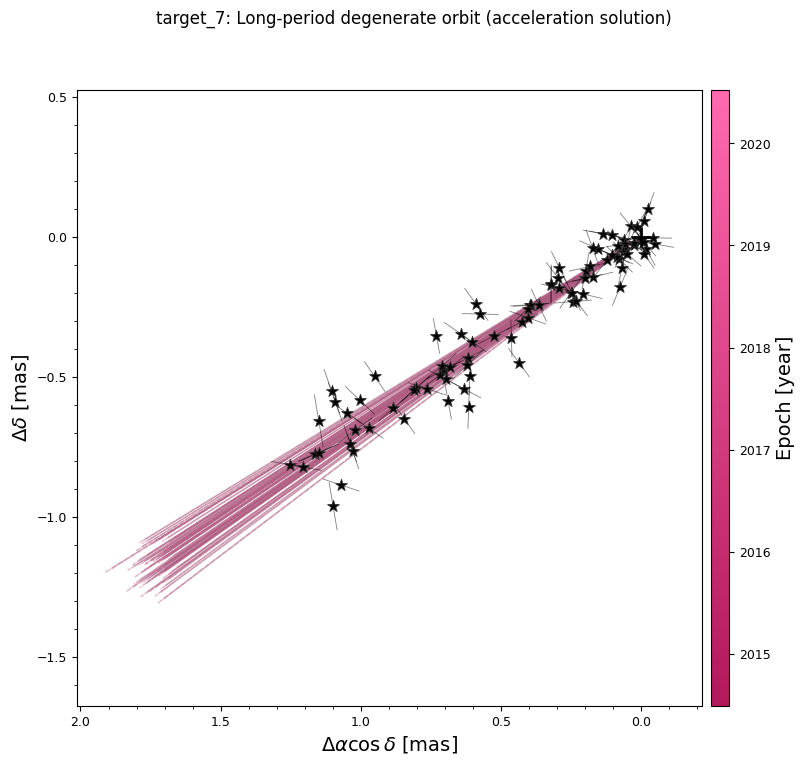

In [24]:
fig = plot.plot_dr4_orbit(
    results, acc_sys, num_orbits_to_plot=50, fontsize=14, show_acceleration=True,
)
fig.suptitle(target_name)
plt.show()

## Without the acceleration

The same posterior as the plot above, drawn with `plot_dr4_orbit(..., remove_acceleration=True)`, which sets `acc_ra = acc_dec = 0` in every plotted sample. The model is then only position + proper motion + parallax, so the pink tracks collapse onto the `+`. The black stars are the data minus that model: the acceleration signal is left in them, spread along each scan direction. If the star had no acceleration, these points would scatter around the `+`.

This is not a refit without acceleration, only the fitted model with its acceleration terms switched off.

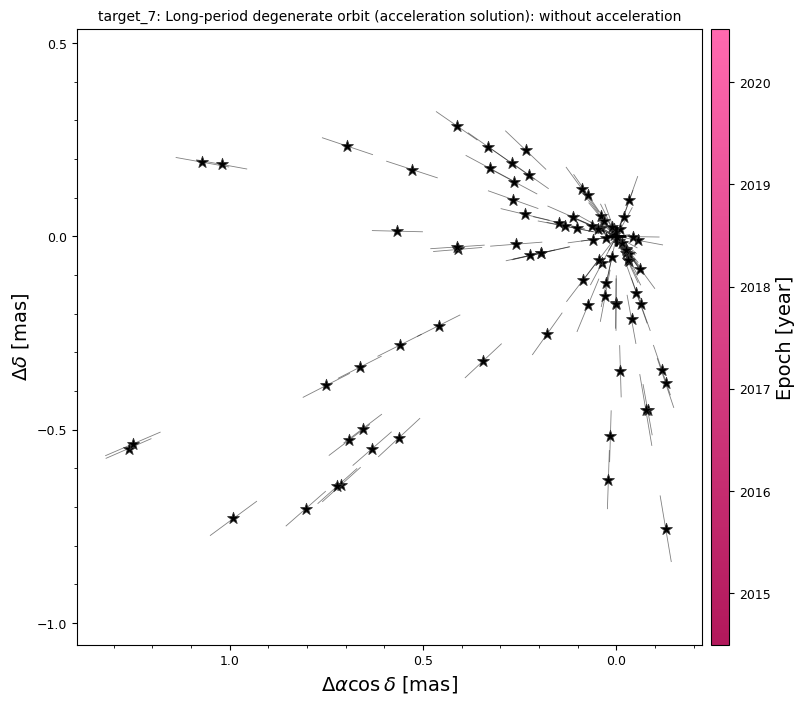

In [25]:
fig = plot.plot_dr4_orbit(
    results, acc_sys, num_orbits_to_plot=50, fontsize=14, remove_acceleration=True,
)
fig.axes[0].set_title(f"{target_name}: without acceleration", fontsize=10)
plt.show()